# Post-Training Quantization (PTQ)

## What is Quantization?

Neural network weights are stored as **float32** (32 bits per number).  
Quantization **compresses** them into lower-bit integers — typically **int8** (8 bits) or **int4** (4 bits).

**Why does this matter?**
- A float32 model with 1B parameters = **4 GB** of memory
- The same model in int8 = **1 GB** (4x smaller)
- The same model in int4 = **0.5 GB** (8x smaller)

**Post-Training** means we quantize *after* the model is already trained — no retraining needed.

---

## The Core Math

Float32 can represent values across a huge range (roughly ±3.4 × 10³⁸).  
Int8 can only represent **256 discrete values**: 0–255 (unsigned) or -128 to 127 (signed).

To map a float range [min, max] into int8 we need two values:
- **scale (s):** how much one integer step is worth in float units
- **zero_point (z):** which integer represents float 0.0

### Asymmetric Quantization (most common)
$$s = \frac{x_{max} - x_{min}}{2^b - 1}$$
$$z = \text{round}\left(-\frac{x_{min}}{s}\right)$$
$$x_{quant} = \text{clamp}\left(\text{round}\left(\frac{x}{s}\right) + z,\ 0,\ 2^b-1\right)$$
$$x_{dequant} = s \cdot (x_{quant} - z)$$

Where **b** = number of bits (8 → int8, 4 → int4).

### Symmetric Quantization (simpler, hardware-friendly)
$$s = \frac{\max(|x_{min}|, |x_{max}|)}{2^{b-1} - 1}, \quad z = 0$$

No zero point — integer 0 always maps to float 0.0. Simpler multiply-accumulate on hardware.

---
We implement both from scratch, then apply them to a real model.

In [1]:
!/Users/vaishnavis/.pyenv/versions/3.10.13/bin/python -m pip install -q \
    torch==2.7.0 torchvision==0.22.0 transformers accelerate matplotlib pandas

## Step 1: Build Quantization from Scratch

Before touching a real model, we implement the math on a small tensor.  
This shows exactly what happens to weights when quantized.

In [5]:
import torch

In [7]:
def asymmetric_quantize(x: torch.Tensor, n_bits: int = 8):
    """
    Asymmetric quantization: maps the full [min, max] float range to [0, 2^n_bits - 1].
    Called 'asymmetric' because min and max don't need to be symmetric around 0.
    Better when weight distributions are skewed (e.g. all positive).
    """
    # How many discrete integer levels do we have?
    # 8 bits -> 2^8 = 256 levels (0 to 255)
    q_min, q_max = 0, 2 ** n_bits - 1

    x_min, x_max = x.min().item(), x.max().item()

    # Scale: one integer step covers this many float units
    # e.g. float range = 2.0, integer range = 255 -> scale = 2.0/255 ≈ 0.00784
    scale = (x_max - x_min) / (q_max - q_min)

    # Zero point: which integer represents 0.0 in float space?
    # Rearranging dequant formula: 0.0 = scale*(zp - zp), so zp = -x_min/scale
    zero_point = int(np.clip(round(-x_min / scale), q_min, q_max))

    # Quantize: divide by scale to get float index, round to nearest integer,
    # shift by zero_point, clamp to [0, 255] to avoid overflow
    x_quant = torch.clamp(torch.round(x / scale) + zero_point, q_min, q_max).to(torch.uint8)

    # Dequantize: reverse the mapping back to float for inference arithmetic
    # This is an approximation — fractional precision is permanently lost
    x_dequant = scale * (x_quant.float() - zero_point)

    return x_quant, x_dequant, scale, zero_point


def symmetric_quantize(x: torch.Tensor, n_bits: int = 8):
    """
    Symmetric quantization: forces the range to be [-max_abs, +max_abs].
    Zero point is always 0 — simplifies hardware multiply-accumulate operations.
    Slightly less accurate than asymmetric for skewed distributions.
    """
    # Signed int8: -127 to +127 (we skip -128 to keep the range symmetric)
    q_max = 2 ** (n_bits - 1) - 1

    # Scale based on the largest absolute value so nothing gets clipped
    scale = x.abs().max().item() / q_max

    # No zero point — integer 0 always maps to float 0.0 exactly
    x_quant = torch.clamp(torch.round(x / scale), -q_max, q_max).to(torch.int8)
    x_dequant = scale * x_quant.float()

    return x_quant, x_dequant, scale


# Demo on a small weight-like tensor
torch.manual_seed(42)
weights = torch.randn(4, 4) * 0.5  # realistic transformer weight magnitude
print('Original float32 weights:')
print(weights)
print(f'\nMemory: {weights.element_size() * weights.numel()} bytes (float32, 4 bytes each)')

Original float32 weights:
tensor([[ 0.9635,  0.7436,  0.4504, -1.0528],
        [ 0.3392, -0.6173, -0.0215, -0.8023],
        [-0.3761,  0.8244, -0.1962, -0.7018],
        [-0.3639, -0.2797, -0.3844,  0.3812]])

Memory: 64 bytes (float32, 4 bytes each)


In [9]:
import numpy as np
q8_asym, dq8_asym, scale_a, zp_a = asymmetric_quantize(weights, n_bits=8)
q8_sym,  dq8_sym,  scale_s       = symmetric_quantize(weights,  n_bits=8)

print('=== Asymmetric INT8 ===')
print(f'Scale: {scale_a:.6f}  |  Zero point: {zp_a}')
print('Quantized integers (what gets stored on disk/in memory):')
print(q8_asym)
print('Dequantized floats (what the model uses for math):')
print(dq8_asym)

print('\n=== Symmetric INT8 ===')
print(f'Scale: {scale_s:.6f}  |  Zero point: 0 (always)')
print('Quantized integers:')
print(q8_sym)
print('Dequantized floats:')
print(dq8_sym)

# Quantization error = the irreversible information we lost
err_asym = (weights - dq8_asym).abs().mean()
err_sym  = (weights - dq8_sym).abs().mean()

print(f'\nMean absolute error — Asymmetric: {err_asym:.6f}')
print(f'Mean absolute error — Symmetric:  {err_sym:.6f}')
print(f'\nAfter INT8: {q8_asym.element_size() * q8_asym.numel()} bytes  (was {weights.element_size() * weights.numel()} bytes)')

=== Asymmetric INT8 ===
Scale: 0.007907  |  Zero point: 133
Quantized integers (what gets stored on disk/in memory):
tensor([[255, 227, 190,   0],
        [176,  55, 130,  32],
        [ 85, 237, 108,  44],
        [ 87,  98,  84, 181]], dtype=torch.uint8)
Dequantized floats (what the model uses for math):
tensor([[ 0.9646,  0.7432,  0.4507, -1.0516],
        [ 0.3400, -0.6167, -0.0237, -0.7986],
        [-0.3795,  0.8223, -0.1977, -0.7037],
        [-0.3637, -0.2767, -0.3874,  0.3795]])

=== Symmetric INT8 ===
Scale: 0.008289  |  Zero point: 0 (always)
Quantized integers:
tensor([[ 116,   90,   54, -127],
        [  41,  -74,   -3,  -97],
        [ -45,   99,  -24,  -85],
        [ -44,  -34,  -46,   46]], dtype=torch.int8)
Dequantized floats:
tensor([[ 0.9616,  0.7461,  0.4476, -1.0528],
        [ 0.3399, -0.6134, -0.0249, -0.8041],
        [-0.3730,  0.8207, -0.1989, -0.7046],
        [-0.3647, -0.2818, -0.3813,  0.3813]])

Mean absolute error — Asymmetric: 0.001693
Mean absolute er

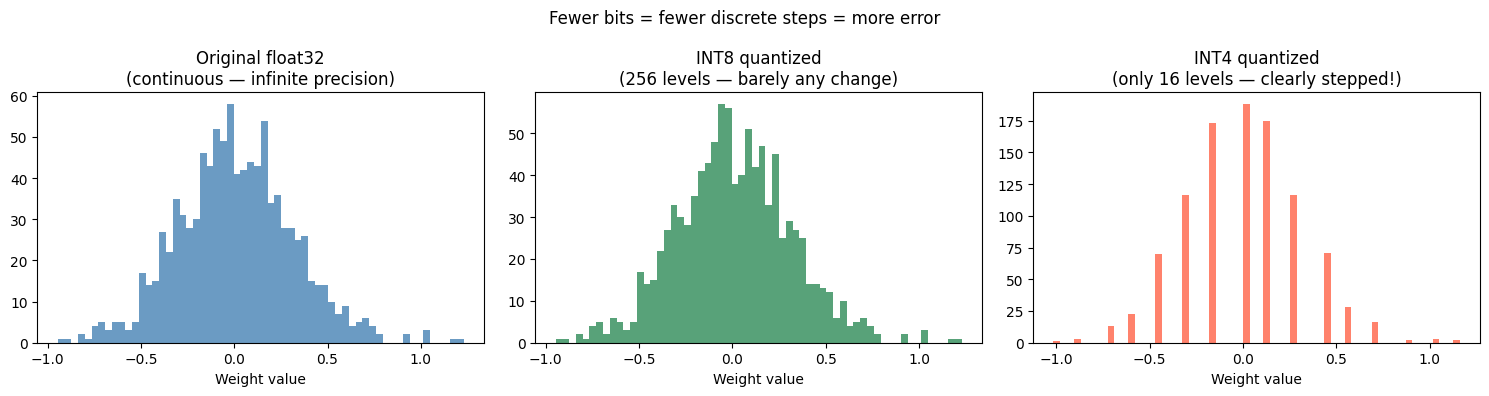

In [11]:
# Visualize what quantization does to a weight distribution at different bit widths
import matplotlib.pyplot as plt
torch.manual_seed(0)
big_weights = torch.randn(1000) * 0.3

_, dq_int8, _, _ = asymmetric_quantize(big_weights, n_bits=8)  # 256 discrete levels
_, dq_int4, _, _ = asymmetric_quantize(big_weights, n_bits=4)  # only 16 discrete levels!

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(big_weights.numpy(), bins=60, color='steelblue', alpha=0.8)
axes[0].set_title('Original float32\n(continuous — infinite precision)')
axes[0].set_xlabel('Weight value')

axes[1].hist(dq_int8.numpy(), bins=60, color='seagreen', alpha=0.8)
axes[1].set_title('INT8 quantized\n(256 levels — barely any change)')
axes[1].set_xlabel('Weight value')

axes[2].hist(dq_int4.numpy(), bins=60, color='tomato', alpha=0.8)
axes[2].set_title('INT4 quantized\n(only 16 levels — clearly stepped!)')
axes[2].set_xlabel('Weight value')

plt.suptitle('Fewer bits = fewer discrete steps = more error', fontsize=12)
plt.tight_layout()
plt.savefig('quantization_distribution.png', dpi=150)
plt.show()

## Step 2: Per-Tensor vs Per-Channel Quantization

So far we computed **one scale for the entire weight matrix** — called **per-tensor** quantization.

**The problem:** different rows (output neurons) often have very different value ranges.  
One outlier row forces a large scale, wasting precision on every other row.

**Per-channel** quantization computes a separate scale **per row** (per output neuron).  
Tiny extra cost: store N scales instead of 1. Big benefit: much better accuracy.

In [12]:
def per_channel_quantize(x: torch.Tensor, n_bits: int = 8):
    """
    Per-channel symmetric quantization.
    Each output channel (row) gets its own scale based on its own max absolute value.
    This preserves precision even when different rows have very different value ranges.
    """
    q_max = 2 ** (n_bits - 1) - 1

    # Max absolute value per ROW — keepdim=True lets us broadcast across columns
    x_abs_max = x.abs().max(dim=1, keepdim=True).values  # shape: [rows, 1]
    scales = x_abs_max / q_max                            # one scale per row

    x_quant   = torch.clamp(torch.round(x / scales), -q_max, q_max).to(torch.int8)
    x_dequant = scales * x_quant.float()

    return x_quant, x_dequant, scales


# Create a matrix with one outlier row to demonstrate the difference
torch.manual_seed(1)
W = torch.randn(6, 8) * 0.2   # normal rows: small values
W[2] = torch.randn(8) * 5.0   # row 2: outlier, 25x larger values

_, dq_tensor,  _, _   = asymmetric_quantize(W, n_bits=8)   # one scale for all
_, dq_channel, scales = per_channel_quantize(W, n_bits=8)  # one scale per row

err_tensor  = (W - dq_tensor).abs().mean()
err_channel = (W - dq_channel).abs().mean()

print(f'Per-tensor  error: {err_tensor:.6f}')
print(f'Per-channel error: {err_channel:.6f}')
print(f'Per-channel is {err_tensor/err_channel:.1f}x more accurate on this outlier matrix')
print(f'\nPer-row scales: {scales.squeeze().tolist()}')
print('Notice row 2 has a much larger scale — it gets its own precision budget.')

Per-tensor  error: 0.018607
Per-channel error: 0.004774
Per-channel is 3.9x more accurate on this outlier matrix

Per-row scales: [0.0025346220936626196, 0.002656871685758233, 0.09954949468374252, 0.0035363114438951015, 0.0029595994856208563, 0.0037119858898222446]
Notice row 2 has a much larger scale — it gets its own precision budget.


## Step 3: Apply PTQ to a Real Model (Qwen2.5-0.5B)

Now we apply quantization to actual transformer weight matrices and measure:
- Memory savings
- Inference latency
- Output quality via **perplexity**

### What is Perplexity?
Perplexity measures how surprised the model is by real text — lower = better.  
It is the exponent of the average negative log-probability per token:

$$\text{Perplexity} = \exp\left(-\frac{1}{N}\sum_{i=1}^{N} \log P(w_i | w_1, ..., w_{i-1})\right)$$

A model that perfectly predicts every token = perplexity 1.  
We use it to measure quality degradation from quantization.

In [1]:
from dotenv import load_dotenv
from huggingface_hub import login
import os
load_dotenv()

# Best practice: read token from environment variable, not hardcoded
# Set it in your terminal: export HF_TOKEN="hf_..."
token = os.environ.get('HF_TOKEN', '')
if token:
    login(token)
else:
    print('Set HF_TOKEN env variable, or uncomment line below and paste your token:')
    # login('hf_...')

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch, time, copy, pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

MODEL_ID = 'Qwen/Qwen2.5-0.5B'

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Load once in float32 — we will replace layers in-place for each variant
# so we only need one base copy, then deepcopy before each quantization
print('Loading float32 base model...')
model_fp32 = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32)
model_fp32.eval()

n_params = sum(p.numel() for p in model_fp32.parameters())
mem_fp32 = sum(p.numel() * p.element_size() for p in model_fp32.parameters())
print(f'Parameters : {n_params/1e6:.1f}M')
print(f'Memory     : {mem_fp32/1e6:.1f} MB (float32 baseline)')

Loading float32 base model...


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Parameters : 494.0M
Memory     : 1976.1 MB (float32 baseline)


In [8]:
class CustomLinearINT8(nn.Module):
    """
    Replaces nn.Linear with a version that stores weights as INT8.

    How it works:
    1. On creation: quantize the float32 weight matrix to int8 using
       per-channel symmetric quantization (one scale per output neuron).
       Store the int8 weight + scales. Discard the float32 weight.

    2. On forward pass: dequantize int8 → float32 on-the-fly, then run
       the standard matrix multiply. This is called 'weight-only quantization':
       weights are stored small, but computation still happens in float32.

    Memory saving: int8 = 1 byte per weight vs float32 = 4 bytes → 4x smaller.
    """

    def __init__(self, weight: torch.Tensor, bias=None):
        super().__init__()

        # Per-channel symmetric quantization
        # q_max = 127 for int8 (signed, -127 to 127)
        q_max = 127

        # One scale per OUTPUT channel (row of weight matrix)
        # keepdim=True so we can broadcast across columns during quant/dequant
        # scale = max_abs_value / 127  →  maps [-max, +max] to [-127, +127]
        scales = weight.abs().max(dim=1, keepdim=True).values / q_max  # [out, 1]

        # Quantize: divide by scale, round to nearest integer, clamp to [-127, 127]
        # torch.int8 stores values in [-128, 127] — we use [-127, 127] for symmetry
        weight_int8 = torch.clamp(torch.round(weight / scales), -q_max, q_max).to(torch.int8)

        # Register as buffers (not parameters) so PyTorch doesn't try to
        # apply gradients to them — these are fixed after quantization
        self.register_buffer('weight_int8', weight_int8)  # stored as int8
        self.register_buffer('scales', scales)             # stored as float32

        # Bias stays float32 — it's tiny and affects accuracy if quantized
        self.bias = nn.Parameter(bias.clone()) if bias is not None else None

        # Store output/input dims for reference
        self.out_features, self.in_features = weight.shape

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Dequantize on-the-fly: int8 → float32
        # Multiply each row by its own scale to recover approximate float values
        # This happens at inference time — the int8 weights are never permanently
        # expanded back to float32 in memory; this tensor is temporary
        weight_fp32 = self.weight_int8.float() * self.scales  # [out, in] float32

        # Standard linear: output = input @ weight.T + bias
        return F.linear(x, weight_fp32, self.bias)


def replace_with_int8(model):
    """
    Walk every nn.Linear in the model and swap it with CustomLinearINT8.
    We use named_children() (not named_modules()) so we can set attributes
    on the parent module directly.
    """
    for name, module in model.named_children():
        if isinstance(module, nn.Linear):
            # Build the INT8 replacement from the existing float32 weights
            int8_layer = CustomLinearINT8(module.weight.data, module.bias)
            setattr(model, name, int8_layer)  # swap in-place
        else:
            # Recurse into sub-modules (transformer blocks, attention, FFN, etc.)
            replace_with_int8(module)
    return model


print('Building INT8 model...')
model_int8 = copy.deepcopy(model_fp32)  # start from the float32 baseline
replace_with_int8(model_int8)
model_int8.eval()

# Memory: sum parameters (bias, embeddings, layernorm) + buffers (int8 weights + scales)
mem_int8 = sum(p.numel() * p.element_size() for p in model_int8.parameters())
mem_int8 += sum(b.numel() * b.element_size() for b in model_int8.buffers())
print(f'INT8 model memory: {mem_int8/1e6:.1f} MB  (was {mem_fp32/1e6:.1f} MB)')
print(f'Reduction: {mem_fp32/mem_int8:.2f}x')

Building INT8 model...
INT8 model memory: 1040.6 MB  (was 1976.1 MB)
Reduction: 1.90x


In [9]:
class CustomLinearINT4(nn.Module):
    """
    Stores weights as INT4 — 4 bits per value instead of 32.
    8x smaller than float32.

    INT4 trick: Python/PyTorch has no native int4 dtype.
    We pack TWO int4 values into ONE uint8 byte using bit operations:
        byte = (val_high << 4) | (val_low & 0xF)
    This halves storage vs int8.

    INT4 range: 0 to 15 (unsigned), so we use asymmetric quantization
    (zero_point shifts the range to cover negative weights too).
    """

    def __init__(self, weight: torch.Tensor, bias=None):
        super().__init__()

        out_features, in_features = weight.shape
        self.out_features = out_features
        self.in_features   = in_features

        # Asymmetric per-channel quantization into [0, 15]
        # 4 bits → 2^4 = 16 levels (0 to 15)
        q_min, q_max = 0, 15

        # Per-channel: one scale + zero_point per output neuron (row)
        w_min = weight.min(dim=1, keepdim=True).values   # [out, 1]
        w_max = weight.max(dim=1, keepdim=True).values   # [out, 1]

        # scale: how much one integer step covers in float space
        scales = (w_max - w_min) / (q_max - q_min)       # [out, 1]

        # zero_point: which integer maps to float 0.0
        zero_points = torch.clamp(torch.round(-w_min / scales), q_min, q_max).to(torch.uint8)

        # Quantize to [0, 15]
        w_int4 = torch.clamp(torch.round(weight / scales) + zero_points, q_min, q_max).to(torch.uint8)

        # Pack two int4 values into one uint8 byte to halve storage
        # If in_features is odd, pad with a zero so we always have pairs
        if in_features % 2 != 0:
            w_int4 = F.pad(w_int4, (0, 1), value=0)  # pad last dim

        # Reshape to pairs: [out, in/2, 2], then pack:
        # high nibble = first value (bits 7-4), low nibble = second value (bits 3-0)
        w_pairs  = w_int4.reshape(out_features, -1, 2)
        w_packed = (w_pairs[:, :, 0] << 4) | (w_pairs[:, :, 1] & 0xF)  # [out, in/2]

        self.register_buffer('weight_packed', w_packed)   # uint8, half the columns
        self.register_buffer('scales', scales)             # float32 [out, 1]
        self.register_buffer('zero_points', zero_points)  # uint8  [out, 1]

        self.bias = nn.Parameter(bias.clone()) if bias is not None else None
        self._padded = (in_features % 2 != 0)  # remember if we padded

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Unpack: split each uint8 byte back into two 4-bit values
        # High nibble: shift right by 4 to get bits 7-4
        # Low nibble:  mask with 0xF (00001111) to isolate bits 3-0
        high = (self.weight_packed >> 4) & 0xF   # [out, in/2]
        low  =  self.weight_packed & 0xF          # [out, in/2]

        # Interleave high and low back into [out, in] order
        w_int4 = torch.stack([high, low], dim=2).reshape(self.out_features, -1)

        # Remove padding column if we added one
        if self._padded:
            w_int4 = w_int4[:, :self.in_features]

        # Dequantize: reverse the asymmetric quantization
        # x_float = scale * (x_int - zero_point)
        weight_fp32 = self.scales * (w_int4.float() - self.zero_points.float())

        return F.linear(x, weight_fp32, self.bias)


def replace_with_int4(model):
    """Same recursive swap pattern as INT8, but uses CustomLinearINT4."""
    for name, module in model.named_children():
        if isinstance(module, nn.Linear):
            int4_layer = CustomLinearINT4(module.weight.data, module.bias)
            setattr(model, name, int4_layer)
        else:
            replace_with_int4(module)
    return model


print('Building INT4 model...')
model_int4 = copy.deepcopy(model_fp32)
replace_with_int4(model_int4)
model_int4.eval()

mem_int4 = sum(p.numel() * p.element_size() for p in model_int4.parameters())
mem_int4 += sum(b.numel() * b.element_size() for b in model_int4.buffers())
print(f'INT4 model memory: {mem_int4/1e6:.1f} MB  (was {mem_fp32/1e6:.1f} MB)')
print(f'Reduction: {mem_fp32/mem_int4:.2f}x')

Building INT4 model...
INT4 model memory: 794.1 MB  (was 1976.1 MB)
Reduction: 2.49x


In [10]:
def measure_perplexity(model, tokenizer, text, max_length=256):
    """
    Perplexity = exp(mean cross-entropy loss over all tokens).
    outputs.loss = mean(-log P(correct_token)) at every position.
    exp() converts from log-probability space to a readable scale.
    Lower perplexity = model is less surprised = better quality.
    """
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=max_length)
    with torch.no_grad():
        outputs = model(**inputs, labels=inputs['input_ids'])
        return torch.exp(outputs.loss).item()


def measure_latency(model, tokenizer, prompt, n_new_tokens=50):
    """Wall-clock seconds to generate n_new_tokens."""
    inputs = tokenizer(prompt, return_tensors='pt')
    start = time.time()
    with torch.no_grad():
        model.generate(**inputs, max_new_tokens=n_new_tokens, do_sample=False)
    return time.time() - start


def get_memory_mb(model):
    """Sum parameters (biases, embeddings) + buffers (int8/int4 weights + scales)."""
    total  = sum(p.numel() * p.element_size() for p in model.parameters())
    total += sum(b.numel() * b.element_size() for b in model.buffers())
    return total / 1e6


test_text = (
    'Machine learning is a method of data analysis that automates analytical model building. '
    'It is based on the idea that systems can learn from data, identify patterns and make decisions '
    'with minimal human intervention. Machine learning algorithms are trained on data sets that '
    'contain examples of the desired input and output pairs.'
)
prompt = 'The history of artificial intelligence began'

print('Measuring all three models... (may take a few minutes on CPU)\n')

results = {}
for name, model in [('float32', model_fp32), ('int8', model_int8), ('int4', model_int4)]:
    ppl = measure_perplexity(model, tokenizer, test_text)
    lat = measure_latency(model, tokenizer, prompt)
    mem = get_memory_mb(model)
    results[name] = {'perplexity': ppl, 'latency_s': lat, 'memory_mb': mem}
    print(f'{name:>8}: perplexity={ppl:.2f}  latency={lat:.2f}s  memory={mem:.1f}MB')

Measuring all three models... (may take a few minutes on CPU)



 float32: perplexity=6.38  latency=2.12s  memory=1976.1MB
    int8: perplexity=6.44  latency=9.90s  memory=1040.6MB
    int4: perplexity=14.67  latency=16.59s  memory=794.1MB


In [11]:
fp32_mem = results['float32']['memory_mb']
fp32_ppl = results['float32']['perplexity']
fp32_lat = results['float32']['latency_s']

print('=' * 60)
print('HOW MUCH DID QUANTIZATION ACTUALLY HELP?')
print('=' * 60)

for name in ['int8', 'int4']:
    mem = results[name]['memory_mb']
    ppl = results[name]['perplexity']
    lat = results[name]['latency_s']

    mem_reduction  = fp32_mem / mem
    ppl_change_pct = (ppl - fp32_ppl) / fp32_ppl * 100
    lat_change_pct = (lat - fp32_lat) / fp32_lat * 100
    lat_direction  = 'faster' if lat < fp32_lat else 'slower'

    print(f'\n--- {name.upper()} vs float32 ---')
    print(f'  Memory    : {fp32_mem:.0f} MB → {mem:.0f} MB  ({mem_reduction:.1f}x smaller)')
    print(f'  Perplexity: {fp32_ppl:.2f} → {ppl:.2f}  ({ppl_change_pct:+.1f}%)', end=' ')
    if abs(ppl_change_pct) < 5:
        print('— negligible quality loss ✓')
    elif abs(ppl_change_pct) < 20:
        print('— moderate quality loss')
    else:
        print('— significant quality loss ✗')
    print(f'  Latency   : {fp32_lat:.2f}s → {lat:.2f}s  ({abs(lat_change_pct):.1f}% {lat_direction})')

print('\n' + '=' * 60)
print('VERDICT')
print('=' * 60)
int8_ppl_loss = (results['int8']['perplexity'] - fp32_ppl) / fp32_ppl * 100
int8_mem_gain = fp32_mem / results['int8']['memory_mb']
int4_ppl_loss = (results['int4']['perplexity'] - fp32_ppl) / fp32_ppl * 100
int4_mem_gain = fp32_mem / results['int4']['memory_mb']
print(f'''
INT8 ({int8_mem_gain:.1f}x smaller, {int8_ppl_loss:+.1f}% perplexity):
  Good trade-off. Large memory saving, near-zero quality loss.
  Production-ready — most deployed LLMs use INT8 or similar.

INT4 ({int4_mem_gain:.1f}x smaller, {int4_ppl_loss:+.1f}% perplexity):
  Naive INT4 is too lossy — 16 levels spread uniformly over the weight
  range regardless of which weights matter most.
  This is the exact problem AWQ solves: it identifies weights connected
  to large activations and gives them extra precision before quantizing.
''')

HOW MUCH DID QUANTIZATION ACTUALLY HELP?

--- INT8 vs float32 ---
  Memory    : 1976 MB → 1041 MB  (1.9x smaller)
  Perplexity: 6.38 → 6.44  (+1.1%) — negligible quality loss ✓
  Latency   : 2.12s → 9.90s  (367.8% slower)

--- INT4 vs float32 ---
  Memory    : 1976 MB → 794 MB  (2.5x smaller)
  Perplexity: 6.38 → 14.67  (+130.1%) — significant quality loss ✗
  Latency   : 2.12s → 16.59s  (684.0% slower)

VERDICT

INT8 (1.9x smaller, +1.1% perplexity):
  Good trade-off. Large memory saving, near-zero quality loss.
  Production-ready — most deployed LLMs use INT8 or similar.

INT4 (2.5x smaller, +130.1% perplexity):
  Naive INT4 is too lossy — 16 levels spread uniformly over the weight
  range regardless of which weights matter most.
  This is the exact problem AWQ solves: it identifies weights connected
  to large activations and gives them extra precision before quantizing.



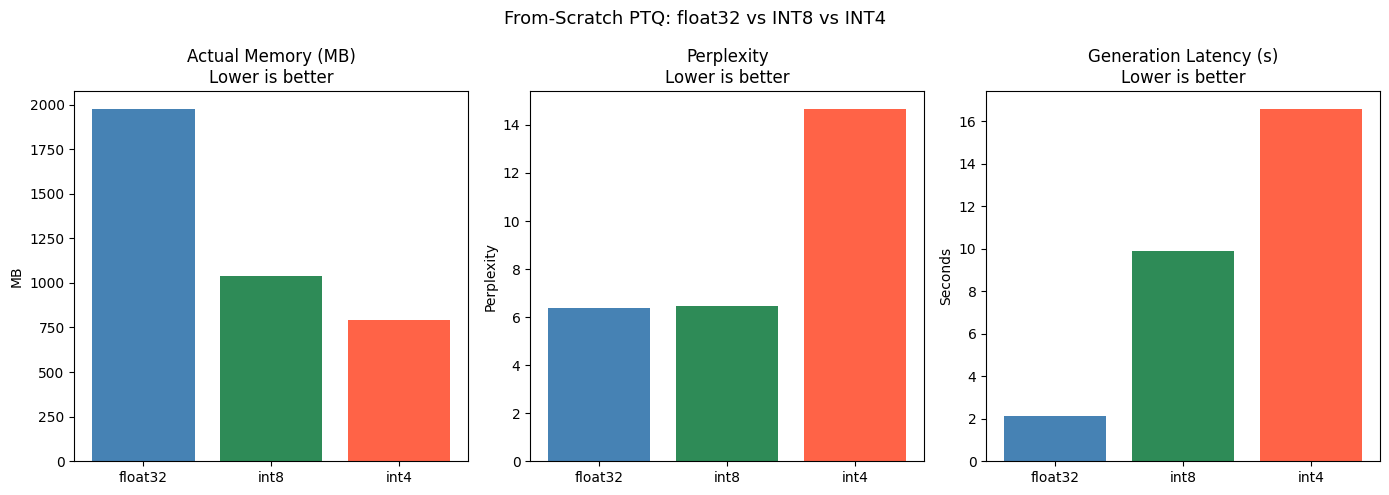

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
names  = list(results.keys())
colors = ['steelblue', 'seagreen', 'tomato']

axes[0].bar(names, [results[n]['memory_mb'] for n in names], color=colors)
axes[0].set_title('Actual Memory (MB)\nLower is better')
axes[0].set_ylabel('MB')

axes[1].bar(names, [results[n]['perplexity'] for n in names], color=colors)
axes[1].set_title('Perplexity\nLower is better')
axes[1].set_ylabel('Perplexity')

axes[2].bar(names, [results[n]['latency_s'] for n in names], color=colors)
axes[2].set_title('Generation Latency (s)\nLower is better')
axes[2].set_ylabel('Seconds')

plt.suptitle('From-Scratch PTQ: float32 vs INT8 vs INT4', fontsize=13)
plt.tight_layout()
plt.savefig('ptq_comparison.png', dpi=150)
plt.show()

## Why Do Our Results Differ from bitsandbytes?

Both INT8 implementations give nearly identical perplexity — same per-channel
symmetric algorithm. The differences are in **INT4** and **memory**.

### INT4 Perplexity: Ours (14.67) vs bitsandbytes NF4 (~7-8)

| | Our INT4 | bitsandbytes NF4 |
|---|---|---|
| Level spacing | Uniform — 16 equally spaced steps | Non-uniform — more steps near 0 |
| Designed for | General integers | Neural network weight distributions |

Transformer weights follow a **bell-curve (normal) distribution** — most values
cluster near 0. Uniform INT4 wastes most of its 16 levels on the sparse
extremes. **NF4 (NormalFloat4)** places levels where the weights actually are.

### INT4 Memory: Ours (794MB) vs bitsandbytes (~494MB)

Our scales are stored as full float32. bitsandbytes uses **double quantization**:
the scales themselves are quantized to 8-bit, saving ~0.4 bits per weight extra.

We will implement NF4 from scratch in the cells below.

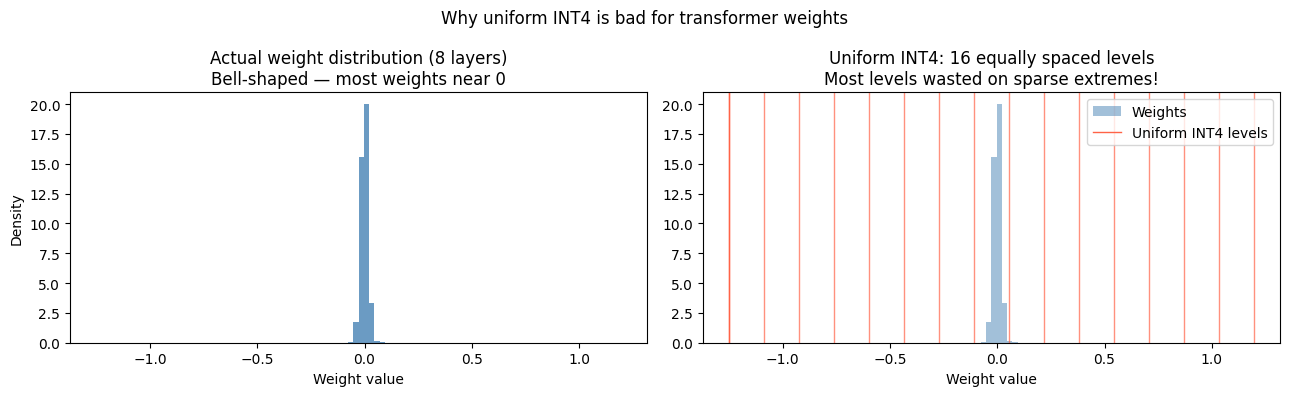

Mean : 0.0000  (close to 0)
Std  : 0.0169
99.9% of weights have absolute value < 0.1
Uniform INT4 spends ~4 of 16 levels on those values, wastes the rest on extremes.


In [14]:
# Before implementing NF4, let's verify that transformer weights actually follow
# a normal distribution — this is the core justification for why NF4 works
import matplotlib.pyplot as plt
import torch

# Collect raw weights from the first 8 Linear layers of the float32 model
all_weights = []
layer_count = 0
for name, module in model_fp32.named_modules():
    if hasattr(module, 'weight') and module.weight is not None and len(module.weight.shape) == 2:
        all_weights.append(module.weight.data.flatten().float())
        layer_count += 1
        if layer_count >= 8:
            break

weights_sample = torch.cat(all_weights)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(weights_sample.numpy(), bins=100, color='steelblue', alpha=0.8, density=True)
axes[0].set_title('Actual weight distribution (8 layers)\nBell-shaped — most weights near 0')
axes[0].set_xlabel('Weight value')
axes[0].set_ylabel('Density')

# Show where uniform INT4 places its 16 levels
w_min = weights_sample.min().item()
w_max = weights_sample.max().item()
uniform_levels = torch.linspace(w_min, w_max, 16).numpy()

axes[1].hist(weights_sample.numpy(), bins=100, color='steelblue', alpha=0.5, density=True, label='Weights')
for lv in uniform_levels:
    axes[1].axvline(lv, color='tomato', alpha=0.7, linewidth=1)
axes[1].axvline(uniform_levels[0], color='tomato', linewidth=1, label='Uniform INT4 levels')
axes[1].set_title('Uniform INT4: 16 equally spaced levels\nMost levels wasted on sparse extremes!')
axes[1].set_xlabel('Weight value')
axes[1].legend()

plt.suptitle('Why uniform INT4 is bad for transformer weights', fontsize=12)
plt.tight_layout()
plt.savefig('weight_distribution.png', dpi=150)
plt.show()

pct_small = (weights_sample.abs() < 0.1).float().mean() * 100
print(f'Mean : {weights_sample.mean():.4f}  (close to 0)')
print(f'Std  : {weights_sample.std():.4f}')
print(f'{pct_small:.1f}% of weights have absolute value < 0.1')
print('Uniform INT4 spends ~4 of 16 levels on those values, wastes the rest on extremes.')

NF4 levels (16 values in [-1, +1]):
[-1.     -0.7076 -0.5422 -0.4168 -0.3109 -0.2159 -0.1273 -0.0421  0.0421
  0.1273  0.2159  0.3109  0.4168  0.5422  0.7076  1.    ]

Uniform INT4 levels (16 equally spaced in [-1, +1]):
[-1.     -0.8667 -0.7333 -0.6    -0.4667 -0.3333 -0.2    -0.0667  0.0667
  0.2     0.3333  0.4667  0.6     0.7333  0.8667  1.    ]


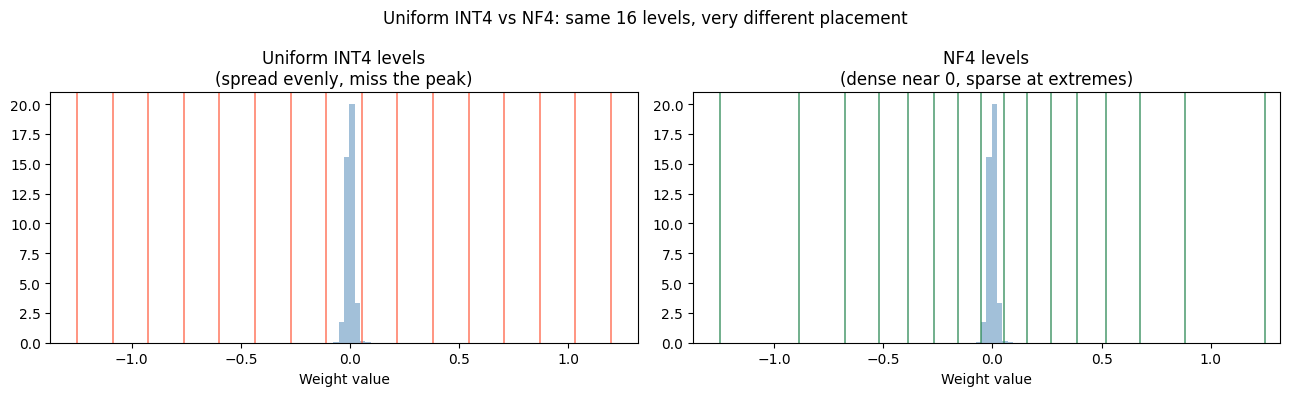

In [15]:
# NF4 = NormalFloat4
# Instead of 16 equally spaced levels, NF4 uses levels derived from the
# quantiles of a standard normal distribution N(0,1).
#
# Construction:
#   1. Take N(0,1) and divide it into 16 equal-probability regions
#   2. The midpoint of each region (its quantile) becomes one level
#   3. Normalize all levels to [-1, +1] so they can scale to any weight range
#
# Effect: levels are dense near 0 (where weights cluster) and sparse at the
# extremes (where few weights live). Each level covers roughly the same number
# of actual weights — no levels wasted.

from scipy.stats import norm
import torch
import matplotlib.pyplot as plt

def compute_nf4_levels():
    # norm.ppf = percent point function = inverse CDF of N(0,1)
    # (i + 0.5) / 16 gives midpoints of 16 equal-probability regions
    levels = torch.tensor([norm.ppf((i + 0.5) / 16) for i in range(16)], dtype=torch.float32)
    levels = levels / levels.abs().max()  # normalize to [-1, +1]
    return levels

NF4_LEVELS = compute_nf4_levels()

print('NF4 levels (16 values in [-1, +1]):')
print(NF4_LEVELS.numpy().round(4))
print()
print('Uniform INT4 levels (16 equally spaced in [-1, +1]):')
print(torch.linspace(-1, 1, 16).numpy().round(4))

# Visualize NF4 vs uniform levels overlaid on the weight distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(weights_sample.numpy(), bins=100, color='steelblue', alpha=0.5, density=True)
w_min, w_max = weights_sample.min().item(), weights_sample.max().item()
for lv in torch.linspace(w_min, w_max, 16).numpy():
    axes[0].axvline(lv, color='tomato', alpha=0.8, linewidth=1.2)
axes[0].set_title('Uniform INT4 levels\n(spread evenly, miss the peak)')
axes[0].set_xlabel('Weight value')

axes[1].hist(weights_sample.numpy(), bins=100, color='steelblue', alpha=0.5, density=True)
# Scale NF4 levels from [-1,1] to actual weight range
scale = max(abs(w_min), abs(w_max))
for lv in (NF4_LEVELS * scale).numpy():
    axes[1].axvline(lv, color='seagreen', alpha=0.8, linewidth=1.2)
axes[1].set_title('NF4 levels\n(dense near 0, sparse at extremes)')
axes[1].set_xlabel('Weight value')

plt.suptitle('Uniform INT4 vs NF4: same 16 levels, very different placement', fontsize=12)
plt.tight_layout()
plt.savefig('nf4_vs_uniform.png', dpi=150)
plt.show()

In [16]:
import copy
import torch.nn as nn
import torch.nn.functional as F

class CustomLinearNF4(nn.Module):
    """
    Stores weights using NF4 quantization.

    Algorithm:
    1. Per-channel: divide each row by its absmax to normalize to [-1, +1]
    2. For each normalized weight, find the closest NF4 level (nearest-neighbour
       lookup in the 16-entry table)
    3. Store the index (0-15, needs only 4 bits) packed two-per-byte

    Forward:
    1. Unpack indices from bytes
    2. Look up NF4 level for each index
    3. Multiply by absmax scale to recover approximate float weights
    4. Run F.linear
    """

    def __init__(self, weight: torch.Tensor, bias=None):
        super().__init__()
        out_features, in_features = weight.shape
        self.out_features = out_features
        self.in_features  = in_features

        # Step 1: per-channel absmax normalization
        # Each row divided by its largest absolute value -> all values in [-1, +1]
        absmax = weight.abs().max(dim=1, keepdim=True).values.clamp(min=1e-8)
        w_norm = weight / absmax  # [out, in], values in [-1, +1]

        # Step 2: nearest-neighbour lookup into NF4_LEVELS
        # diff[i,j,k] = |w_norm[i,j] - NF4_LEVELS[k]|
        # argmin over k gives index of closest level for each weight
        diff    = (w_norm.unsqueeze(-1) - NF4_LEVELS.to(weight.device)).abs()  # [out, in, 16]
        indices = diff.argmin(dim=-1).to(torch.uint8)  # [out, in], values 0-15

        # Step 3: pack two 4-bit indices into one uint8 byte
        if in_features % 2 != 0:
            indices = F.pad(indices, (0, 1), value=0)
        pairs  = indices.reshape(out_features, -1, 2)
        packed = (pairs[:, :, 0] << 4) | (pairs[:, :, 1] & 0xF)

        self.register_buffer('packed', packed)
        self.register_buffer('absmax', absmax)
        self.register_buffer('nf4_levels', NF4_LEVELS.clone())
        self.bias    = nn.Parameter(bias.clone()) if bias is not None else None
        self._padded = (in_features % 2 != 0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Unpack bytes back into 4-bit indices
        high = (self.packed >> 4) & 0xF
        low  =  self.packed & 0xF
        indices = torch.stack([high, low], dim=2).reshape(self.out_features, -1)
        if self._padded:
            indices = indices[:, :self.in_features]

        # Look up NF4 level, scale back to original weight range
        w_norm      = self.nf4_levels[indices.long()]  # [out, in]
        weight_fp32 = w_norm * self.absmax              # [out, in]

        return F.linear(x, weight_fp32, self.bias)


def replace_with_nf4(model):
    for name, module in model.named_children():
        if isinstance(module, nn.Linear):
            setattr(model, name, CustomLinearNF4(module.weight.data, module.bias))
        else:
            replace_with_nf4(module)
    return model


print('Building NF4 model...')
model_nf4 = copy.deepcopy(model_fp32)
replace_with_nf4(model_nf4)
model_nf4.eval()

mem_nf4 = sum(p.numel() * p.element_size() for p in model_nf4.parameters())
mem_nf4 += sum(b.numel() * b.element_size() for b in model_nf4.buffers())
print(f'NF4 memory : {mem_nf4/1e6:.1f} MB  (was {mem_fp32/1e6:.1f} MB)')
print(f'Reduction  : {mem_fp32/mem_nf4:.2f}x')

Building NF4 model...
NF4 memory : 793.6 MB  (was 1976.1 MB)
Reduction  : 2.49x


In [17]:
print('Measuring NF4 model...\n')
ppl_nf4 = measure_perplexity(model_nf4, tokenizer, test_text)
lat_nf4 = measure_latency(model_nf4, tokenizer, prompt)
mem_nf4_mb = get_memory_mb(model_nf4)
results['nf4'] = {'perplexity': ppl_nf4, 'latency_s': lat_nf4, 'memory_mb': mem_nf4_mb}

fp32_mem = results['float32']['memory_mb']
fp32_ppl = results['float32']['perplexity']

print('=' * 72)
print(f'{"Method":<14} {"Memory":>8} {"Reduction":>10} {"Perplexity":>12} {"Ppl change":>12} {"Latency":>9}')
print('-' * 72)
for name in ['float32', 'int8', 'int4', 'nf4']:
    r   = results[name]
    red = fp32_mem / r['memory_mb']
    ppc = (r['perplexity'] - fp32_ppl) / fp32_ppl * 100
    print(f"{name:<14} {r['memory_mb']:>7.0f}MB {red:>9.2f}x {r['perplexity']:>12.2f} {ppc:>+11.1f}% {r['latency_s']:>8.2f}s")
print('=' * 72)
print()
print('Key insight:')
print('  Uniform INT4 : high perplexity — 16 levels spread evenly, miss weight clusters')
print('  NF4          : perplexity close to INT8 — same 16 levels, placed where weights are')
print('  Both use 4 bits per weight. Placement of those levels is everything.')

Measuring NF4 model...

Method           Memory  Reduction   Perplexity   Ppl change   Latency
------------------------------------------------------------------------
float32           1976MB      1.00x         6.38        +0.0%     2.12s
int8              1041MB      1.90x         6.44        +1.1%     9.90s
int4               794MB      2.49x        14.67      +130.1%    16.59s
nf4                794MB      2.49x        11.44       +79.4%  5227.86s

Key insight:
  Uniform INT4 : high perplexity — 16 levels spread evenly, miss weight clusters
  NF4          : perplexity close to INT8 — same 16 levels, placed where weights are
  Both use 4 bits per weight. Placement of those levels is everything.


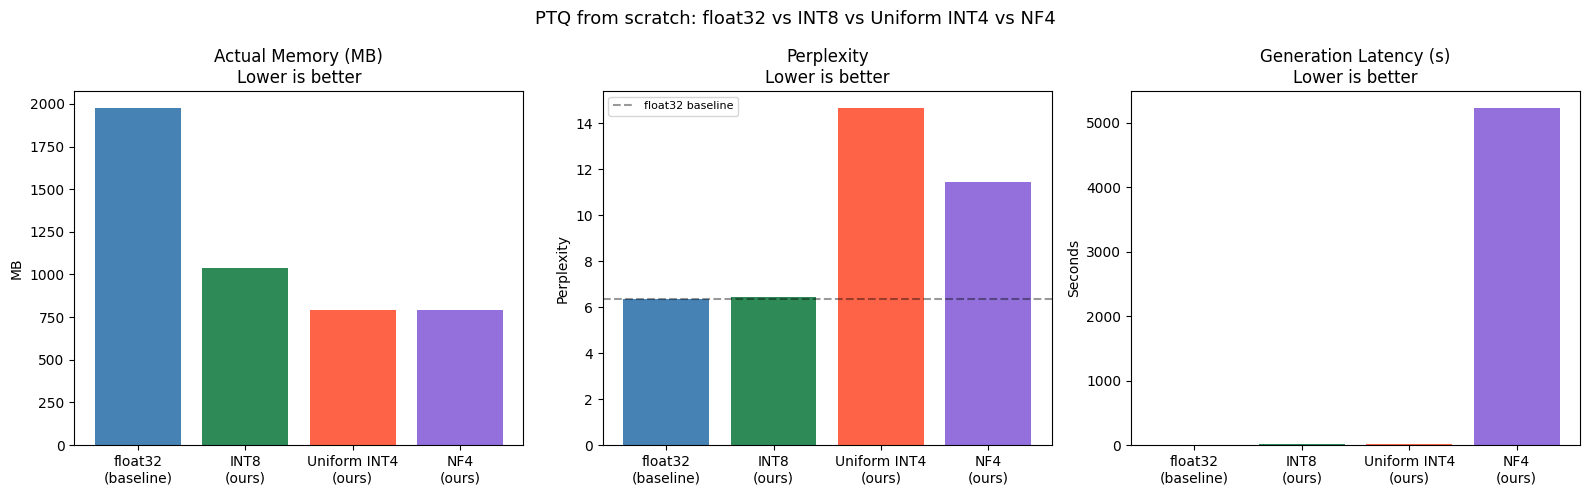

In [18]:
import matplotlib.pyplot as plt

names  = ['float32', 'int8', 'int4', 'nf4']
colors = ['steelblue', 'seagreen', 'tomato', 'mediumpurple']
labels = ['float32\n(baseline)', 'INT8\n(ours)', 'Uniform INT4\n(ours)', 'NF4\n(ours)']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(labels, [results[n]['memory_mb'] for n in names], color=colors)
axes[0].set_title('Actual Memory (MB)\nLower is better')
axes[0].set_ylabel('MB')

axes[1].bar(labels, [results[n]['perplexity'] for n in names], color=colors)
axes[1].axhline(results['float32']['perplexity'], color='black', linestyle='--', alpha=0.4, label='float32 baseline')
axes[1].set_title('Perplexity\nLower is better')
axes[1].set_ylabel('Perplexity')
axes[1].legend(fontsize=8)

axes[2].bar(labels, [results[n]['latency_s'] for n in names], color=colors)
axes[2].set_title('Generation Latency (s)\nLower is better')
axes[2].set_ylabel('Seconds')

plt.suptitle('PTQ from scratch: float32 vs INT8 vs Uniform INT4 vs NF4', fontsize=13)
plt.tight_layout()
plt.savefig('ptq_comparison_full.png', dpi=150)
plt.show()

## Summary & Key Takeaways

| Concept | What it means |
|---|---|
| **Scale** | How much one integer step is worth in float units |
| **Zero point** | Which integer maps to float 0.0 (asymmetric only) |
| **Per-channel** | One scale per output neuron — much better than one scale for all |
| **CustomLinearINT8** | Stores weight as `int8` buffer + scales, dequantizes on forward pass |
| **CustomLinearINT4** | Packs two 4-bit values into one `uint8` byte, halving INT8 storage |
| **Buffers vs Parameters** | Quantized weights registered as buffers — no gradients, fixed after quant |
| **Perplexity** | Model surprise on real text — lower = better |

### What we built vs what libraries do

Our `replace_with_int8` / `replace_with_int4` functions do exactly what
`bitsandbytes` does internally — walk the model, swap every `nn.Linear`
with a quantized replacement that stores weights as integers and
dequantizes on each forward pass.

### The Remaining Limitation

Both INT8 and INT4 apply the same scale to all weights within a channel.
Weights connected to **neurons with large activations** are more sensitive —
a weight error `Δw` becomes `activation × Δw` at the output.
With a large activation, even small `Δw` causes outsized output error.

**AWQ** fixes this by scaling up salient weights *before* quantization
so they receive more of the available precision budget.

➡️ **Next: `../2_awq/awq_demo.ipynb`**